# EXPEDIA — Báo cáo hiểu sâu dữ liệu

**Phạm vi: EDA trên dữ liệu gốc; chưa feature engineering, chưa huấn luyện mô hình.**

Báo cáo có từ điển dữ liệu, kiểm tra chất lượng/khóa/nhãn, thống kê theo nhóm, thời gian và giới hạn suy rộng. Các kết quả được tính lại từ CSV; bản đọc nhanh nằm ở `reports/EXPEDIA/README.md`.

Mọi phân nhóm tạm thời chỉ phục vụ mô tả, không tạo tập feature. Chạy tất cả các cell theo thứ tự; cell đầu quét dữ liệu đầy đủ nên có thể mất vài phút với Expedia.

In [1]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'raw').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Không tìm thấy data/raw; hãy mở notebook trong dự án Propensity.')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('EXPEDIA', PROJECT_ROOT)
print('Đã tính lại từ CSV raw; số chính:', report.facts)
print('Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.')

train.csv: 250,000 rows
train.csv: 500,000 rows
train.csv: 750,000 rows
train.csv: 1,000,000 rows
train.csv: 1,250,000 rows
train.csv: 1,500,000 rows
train.csv: 1,750,000 rows
train.csv: 2,000,000 rows
train.csv: 2,250,000 rows
train.csv: 2,500,000 rows
train.csv: 2,750,000 rows
train.csv: 3,000,000 rows
train.csv: 3,250,000 rows
train.csv: 3,500,000 rows
train.csv: 3,750,000 rows
train.csv: 4,000,000 rows
train.csv: 4,250,000 rows
train.csv: 4,500,000 rows
train.csv: 4,750,000 rows
train.csv: 5,000,000 rows
train.csv: 5,250,000 rows
train.csv: 5,500,000 rows
train.csv: 5,750,000 rows
train.csv: 6,000,000 rows
train.csv: 6,250,000 rows
train.csv: 6,500,000 rows
train.csv: 6,750,000 rows
train.csv: 7,000,000 rows
train.csv: 7,250,000 rows
train.csv: 7,500,000 rows
train.csv: 7,750,000 rows
train.csv: 8,000,000 rows
train.csv: 8,250,000 rows
train.csv: 8,500,000 rows
train.csv: 8,750,000 rows
train.csv: 9,000,000 rows
train.csv: 9,250,000 rows
train.csv: 9,500,000 rows
train.csv: 9,750,0

## 1. Nguồn, đơn vị quan sát và câu hỏi propensity

In [2]:
eda.show_section(report, 'scope')

Schema hiện có thuộc [Personalize Expedia Hotel Searches — ICDM 2013](https://www.kaggle.com/c/expedia-personalized-sort/data), khác cuộc thi Expedia Hotel Recommendations dự đoán hotel cluster. Train có **9,917,530 dòng, 54 cột**; test có **6,622,629 dòng, 50 cột**. Mỗi dòng là một cặp **search–property**, không phải một khách hàng hoặc một lượt search độc lập.

Hai nhãn là `click_bool` và `booking_bool`. Phù hợp với click/booking propensity trong ngữ cảnh danh sách tìm kiếm, hoặc nghiên cứu xếp hạng. Không có ID người dùng để trực tiếp hình thành bài toán CRM theo khách hàng; `srch_id` chỉ định danh lượt tìm kiếm.

Câu hỏi EDA: cấu trúc nhóm, quan hệ click–booking, khác biệt tỷ lệ theo ngữ cảnh/khách sạn/vị trí, thiếu dữ liệu theo nhóm cột, khác train–test, và giới hạn suy rộng tỷ lệ từ tập dữ liệu quan sát.

**Danh mục file; ba benchmark là thứ tự kết quả trên test, không phải dữ liệu train bổ sung**

,file,data_lines,columns,bytes,sha256
0,basicPythonBenchmark.csv,6622629,2,92985279,7de0c115bd3a2a90bc9db65f4679233c0088a2b334868a...
1,randomBenchmark.csv,6622629,2,92985279,5f28a62102d125a406cdd397181205b4b7af8ceb417e6e...
2,test.csv,6622629,50,1496916672,be1d56681726315393c829f7c94f85d4f8c886748a903e...
3,testOrderBenchmark.csv,6622629,2,92985279,42ecaf9f4bbca6ed62be0e3199523151e513584d39fa5d...
4,train.csv,9917530,54,2358114793,84a53139ea92df1e9400f84852facbd78f3136f366a084...


## 2. Từ điển đủ 54 cột và schema train–test

In [3]:
eda.show_section(report, 'dictionary')

Các ID được đọc thành số nhưng mang ý nghĩa phân loại. Nhóm đối thủ có **8 × 3 = 24 cột**, không phải 16. Bốn cột chỉ có ở train là position, click_bool, booking_bool, gross_bookings_usd. Sau khi tách bốn cột này, có 50 cột chung với test; đây là số cột schema, chưa phải số feature được phê duyệt sử dụng. Nếu srch_id chỉ làm khóa nhóm thì còn 49 cột ứng viên; prop_id vẫn cần quyết định cách dùng phù hợp ở giai đoạn sau.

**Schema và missing toàn bộ train**

,column,pandas_dtype,full_missing_n,full_missing_pct,in_test,meaning,role_or_caution
0,srch_id,int64,0,0.0000,True,ID lượt tìm kiếm,"Khóa nhóm, không phải ID người dùng"
1,date_time,object,0,0.0000,True,Thời điểm tìm kiếm,"Thời gian, không giả định timezone không được ..."
2,site_id,int64,0,0.0000,True,ID website/điểm bán Expedia,Phân loại
3,visitor_location_country_id,int64,0,0.0000,True,ID quốc gia vị trí người tìm,"Phân loại, không phải mã có thứ tự"
4,visitor_hist_starrating,float64,9412233,94.9050,True,Mức sao trung bình trong lịch sử khách,NA không đủ chứng minh khách mới/chưa đăng nhập
5,visitor_hist_adr_usd,float64,9409918,94.8817,True,"ADR lịch sử của khách, USD",Cần xác minh cửa sổ lịch sử và cách tính
6,prop_country_id,int64,0,0.0000,True,ID quốc gia khách sạn,Phân loại
7,prop_id,int64,0,0.0000,True,ID khách sạn,Thực thể có thể lặp qua searches; không phải s...
8,prop_starrating,int64,0,0.0000,True,Hạng sao khách sạn,0 cần xác minh nghĩa; không tự xem là 0 sao ch...
9,prop_review_score,float64,14630,0.1475,True,Điểm review khách sạn,0 và NA là hai trường hợp cần phân biệt


## 3. Phương pháp tính: toàn bộ dữ liệu và mẫu nhóm

In [4]:
eda.show_section(report, 'method')

**Toàn bộ train và test được quét theo chunk 250,000 dòng.** Số dòng/nhóm, missing, tỷ lệ nhãn, thống kê mean/std/min/max, phân bố category, bảng nhóm và chuỗi thời gian đều được cộng dồn trên toàn file; không thay toàn bộ dữ liệu bằng 500.000 dòng đầu.

**Chỉ các percentile và biểu đồ phân phối trên mẫu** dùng mẫu xác định bằng `hash_pandas_object(srch_id, index=False) % 20 == 0`, tỷ lệ mục tiêu khoảng 5%. Tất cả khách sạn cùng srch_id được giữ cùng nhau, kể cả khi nhóm vượt ranh giới chunk. Mẫu train thực tế có **493,340 dòng / 19,841 searches**. Đây là mẫu nhóm bằng hàm băm có thể tái lập, không khẳng định đại diện tuyệt đối hoặc là lấy mẫu ngẫu nhiên đơn từng dòng. Thuật toán hash phụ thuộc phiên bản pandas nên môi trường được ghi ở cuối báo cáo.

Giá trị `sample_p*` được gắn nhãn riêng, không trộn với thống kê `full_*`. Khóa ghép (srch_id,prop_id) được kiểm tra trùng bằng cặp ID thật, không dùng va chạm hash để kết luận duplicate. Danh mục file có SHA-256 để nhận diện đúng phiên bản nguồn.

**Đối chiếu mẫu nhóm với toàn bộ train**

,population,rows,searches,click_pct,booking_pct
0,train: toàn bộ,9917530,399344,4.4736,2.7889
1,train: mẫu hash theo nhóm,493340,19841,4.4847,2.7802


## 4. Cấu trúc nhóm, nhãn và giới hạn quần thể

In [5]:
eda.show_section(report, 'quality')

Train gồm **399,344 searches**, trung bình **24.83 khách sạn/search**. Có **0 search không click** trong tập train. Vì vậy tập đang phân tích không có nhóm search hoàn toàn không tương tác; không ước lượng tỷ lệ mọi người dùng trên website quyết định click từ tỷ lệ 4–5% trên các dòng này.

Trong raw, mọi booking đều có click ở cùng cặp search–property; tỷ số bookings/clicks là thống kê có điều kiện đúng trên tập hiện tại. Nó không chứng minh việc làm tăng click sẽ gây tăng booking, không tự xác lập chiến lược marketing hay hiệu quả triển khai.

`gross_bookings_usd` là thông tin sau booking. Giá trị hiện diện chỉ ở dòng có booking; có 1 booking bị thiếu gross. Không impute cột kết quả này thành feature. `position` là vị trí hiển thị quan sát được và không có trong test. Click thực tế không phải đầu vào hợp lệ của mô hình dự đoán trước click.

Các dòng trong một search phụ thuộc nhau. Vì vậy không đưa khoảng tin cậy nhị thức giả định mọi impression độc lập; nếu cần suy luận ở giai đoạn sau, phải xét cấu trúc nhóm. Nhóm khóa không trùng không đồng nghĩa người dùng độc lập vì không có user ID.

**Kích thước danh sách theo search**

,population,searches,mean_properties,median_properties,min_properties,max_properties,searches_multiple_timestamps
0,train,399344,24.8346,29.0000,5,38,0
1,test,266230,24.8756,29.0000,5,37,0


**Kiểm tra khóa và tính nhất quán kết quả**

,check,n
0,Train: cặp srch_id-prop_id trùng (beyond first),0
1,Test: cặp srch_id-prop_id trùng,0
2,srch_id xuất hiện cả train và test,0
3,prop_id xuất hiện cả train và test,128953
4,Train: search không click,0
5,Train: search có >1 booking,0
6,Train: booking=1 nhưng click=0,0
7,Train: booking=1 nhưng gross thiếu,1
8,Train: booking=0 nhưng gross có giá trị,0
9,"Train: nhãn ngoài {0,1} hoặc thiếu",0


**Tỷ lệ với tử số/mẫu số cụ thể — toàn bộ train**

,metric,numerator,denominator,pct
0,Click / cặp search-property,443672,9917530,4.4736
1,Booking / cặp search-property,276593,9917530,2.7889
2,Booking / cặp đã click,276593,443672,62.3418
3,Search có booking / toàn bộ search train,276593,399344,69.2618


## 5. Missing, giá trị đặc biệt và chất lượng giá

In [6]:
eda.show_section(report, 'missing')

Missing được trình bày đủ các cột ở phần schema, với so sánh train–test bên dưới. Nhóm comp có mức thiếu rất khác nhau theo đối thủ và loại thuộc tính; không suy từ top 15 cột thiếu nhiều nhất rằng cả nhóm đều thiếu >93%. Không có dữ liệu đối thủ không chứng minh khách sạn không có đối thủ. Thiếu lịch sử khách không đủ để kết luận khách mới/chưa đăng nhập. Giá 0 và giá cực lớn được định lượng bằng ngưỡng kiểm tra công bố trước; không tự kết luận lỗi, đổi đơn vị hoặc clipping. Định nghĩa giá theo đêm/toàn kỳ chưa được xác minh từ CSV.

**Toàn bộ 24 cột đối thủ — missing theo tập**

,column,train_missing_pct,test_missing_pct
27,comp1_rate,97.6223,97.6586
28,comp1_inv,97.4345,97.4743
29,comp1_rate_percent_diff,98.1356,98.1560
30,comp2_rate,59.2577,59.2359
31,comp2_inv,57.1311,57.1107
32,comp2_rate_percent_diff,88.8092,88.7749
33,comp3_rate,69.1529,69.3113
34,comp3_inv,66.8040,66.9643
35,comp3_rate_percent_diff,90.4814,90.5214
36,comp4_rate,93.7474,93.6915


**Missing các cột ngoài comp**

,column,train_missing_pct,test_missing_pct
0,srch_id,0.0000,0.0000
1,date_time,0.0000,0.0000
2,site_id,0.0000,0.0000
3,visitor_location_country_id,0.0000,0.0000
4,visitor_hist_starrating,94.9050,94.8589
5,visitor_hist_adr_usd,94.8817,94.8282
6,prop_country_id,0.0000,0.0000
7,prop_id,0.0000,0.0000
8,prop_starrating,0.0000,0.0000
9,prop_review_score,0.1475,0.1442


**Kiểm tra đuôi giá trên toàn bộ dữ liệu**

,population,rows,price_zero,price_negative,price_above_1000,price_above_10000
0,train,9917530,54,0,27018,3936
1,test,6622629,80,0,17251,2628


## 6. Phân phối định lượng và phân loại

Các cột full_* dùng toàn bộ dữ liệu. Các cột sample_p* là percentile trên mẫu nhóm đã mô tả, không phải percentile chính xác toàn bộ file. Mean/std có thể rất nhạy với giá cực lớn; đọc cùng median/p95/p99 trên mẫu và full max. Tỷ trọng category dưới đây tính theo cặp search-property, không phải tỷ trọng khách hoặc tỷ trọng search; search có nhiều khách sạn đóng góp nhiều dòng hơn.

**Train: thống kê toàn bộ và percentile mẫu có nhãn riêng**

,column,full_count_nonnull,full_mean,full_std,full_min,full_max,sample_p1,sample_p25,sample_p50,sample_p75,sample_p95,sample_p99
0,visitor_hist_starrating,505297,3.3746,0.6922,1.0000,5.0000,2.0000,2.8300,3.4400,3.9300,4.4900,5.0000
1,visitor_hist_adr_usd,507612,176.5885,108.4348,0.0000,"2,768.9300",47.2100,112.7600,150.9300,207.8000,358.7500,579.1000
2,prop_starrating,9917530,3.1815,1.0502,0.0000,5.0000,0.0000,3.0000,3.0000,4.0000,5.0000,5.0000
3,prop_review_score,9902900,3.7777,1.0508,0.0000,5.0000,0.0000,3.5000,4.0000,4.5000,4.5000,5.0000
4,prop_location_score1,9917530,2.8760,1.5321,0.0000,6.9800,0.0000,1.7900,2.7700,4.0600,5.5800,6.3200
5,prop_location_score2,7739150,0.1304,0.1595,0.0000,1.0000,0.0003,0.0190,0.0689,0.1787,0.4775,0.7194
6,prop_log_historical_price,9917530,4.3168,1.8362,0.0000,6.2100,0.0000,4.4500,4.9200,5.3200,5.9300,6.2100
7,price_usd,9917530,241.7825,"14,341.8095",0.0000,"19,726,328.0000",33.4400,85.0000,122.0000,185.8000,356.0000,597.0000
8,srch_length_of_stay,9917530,2.3900,2.0668,1.0000,59.0000,1.0000,1.0000,2.0000,3.0000,6.0000,10.0000
9,srch_booking_window,9917530,37.6238,52.1080,0.0000,498.0000,0.0000,4.0000,17.0000,50.0000,155.0000,244.0000


**Test: cùng phương pháp thống kê**

,column,full_count_nonnull,full_mean,full_std,full_min,full_max,sample_p1,sample_p25,sample_p50,sample_p75,sample_p95,sample_p99
0,visitor_hist_starrating,340476,3.3564,0.6912,1.0000,5.0000,2.0000,2.8800,3.3300,3.8600,4.5000,5.0000
1,visitor_hist_adr_usd,342511,174.5589,106.9481,0.0000,"1,654.9200",29.9500,105.6500,148.8000,210.3800,351.3100,632.1800
2,prop_starrating,6622629,3.1824,1.0484,0.0000,5.0000,0.0000,3.0000,3.0000,4.0000,5.0000,5.0000
3,prop_review_score,6613080,3.7800,1.0479,0.0000,5.0000,0.0000,3.5000,4.0000,4.5000,4.5000,5.0000
4,prop_location_score1,6622629,2.8814,1.5332,0.0000,6.9800,0.0000,1.7900,2.7700,4.0400,5.5800,6.3100
5,prop_location_score2,5167707,0.1305,0.1595,0.0000,1.0000,0.0003,0.0192,0.0691,0.1779,0.4703,0.7148
6,prop_log_historical_price,6622629,4.3164,1.8355,0.0000,6.2100,0.0000,4.4500,4.9100,5.3200,5.9300,6.2100
7,price_usd,6622629,213.0988,"8,332.4874",0.0000,"5,513,008.0000",34.9284,85.0000,121.6100,184.0000,352.0000,589.0000
8,srch_length_of_stay,6622629,2.3845,2.0462,1.0000,50.0000,1.0000,1.0000,2.0000,3.0000,6.0000,10.0000
9,srch_booking_window,6622629,37.5551,51.9371,0.0000,498.0000,0.0000,4.0000,16.0000,48.0000,151.0000,244.0000


**Top 12 category/cột — toàn bộ train**

,column,value,n,pct_all_rows
0,site_id,5,6164803,62.1607
1,site_id,14,964105,9.7212
2,site_id,15,618620,6.2376
3,site_id,24,475893,4.7985
4,site_id,32,355805,3.5876
5,site_id,18,258751,2.6090
6,site_id,16,181436,1.8294
7,site_id,12,148636,1.4987
8,site_id,19,82566,0.8325
9,site_id,9,82298,0.8298


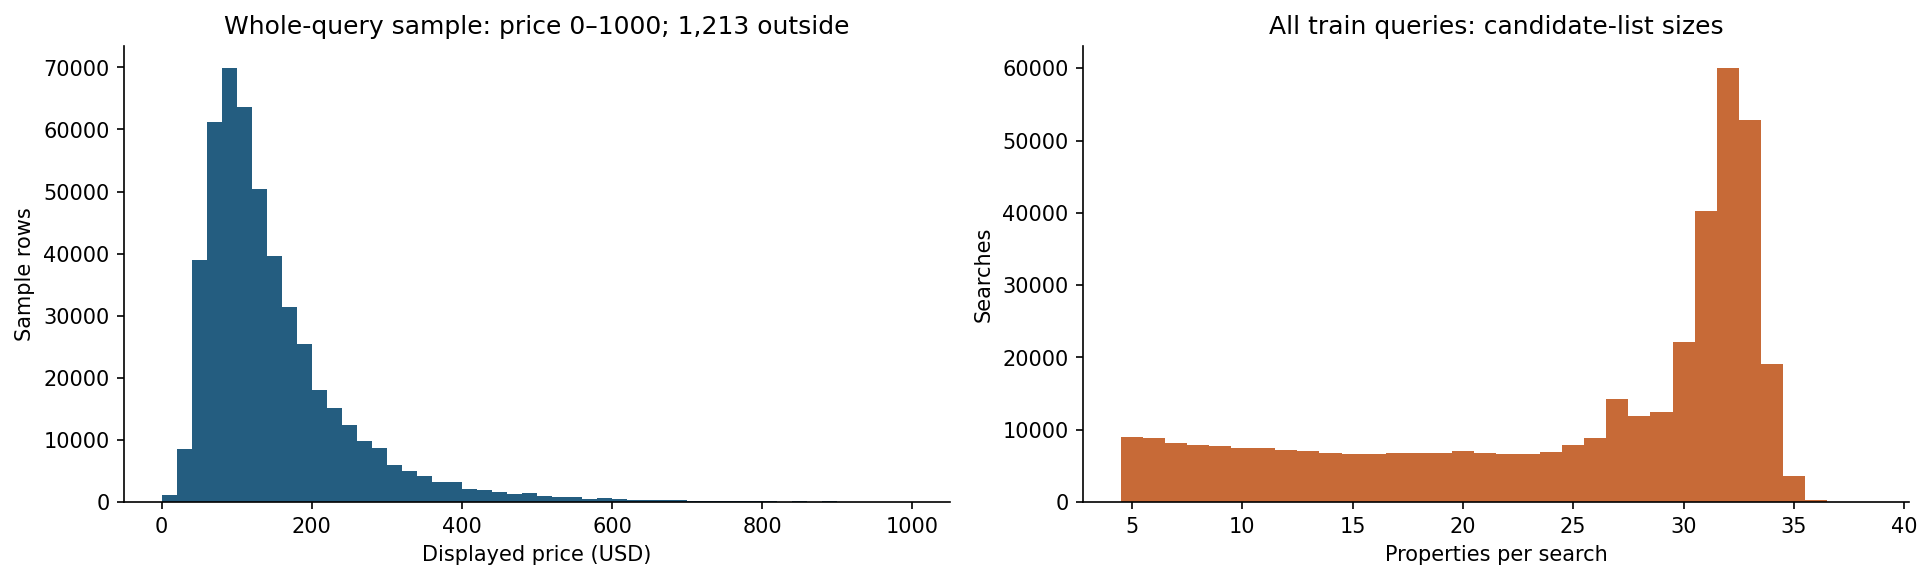

In [7]:
eda.show_section(report, 'distributions')

## 7. Mối liên hệ với click/booking theo nhóm

In [8]:
eda.show_section(report, 'target')

Tất cả bảng dùng toàn bộ train. Phân nhóm giá và booking window chỉ là công cụ đọc bảng EDA; không xuất feature. Tỷ lệ có thể phản ánh vị trí hiển thị, thành phần search, thương hiệu, thời gian và cơ chế chọn mẫu cùng lúc. Không coi chênh lệch promotion_flag là uplift từ khuyến mãi. Bảng không kiểm định nhiều giả thuyết hoặc khẳng định quan hệ nhân quả.

**Tỷ lệ click/booking theo prop_starrating; mẫu số là số cặp trong nhóm**

,prop_starrating,n,clicks,bookings,click_pct,booking_pct,n_under_100
0,0,337794,9792,5582,2.8988,1.6525,False
1,1,34514,965,439,2.7960,1.2719,False
2,2,1788994,60596,38892,3.3872,2.1740,False
3,3,3897419,170869,109049,4.3842,2.7980,False
4,4,3045848,164118,101691,5.3883,3.3387,False
5,5,812961,37332,20940,4.5921,2.5758,False


**Tỷ lệ click/booking theo prop_brand_bool; mẫu số là số cặp trong nhóm**

,prop_brand_bool,n,clicks,bookings,click_pct,booking_pct,n_under_100
0,0,3626799,160997,92903,4.4391,2.5616,False
1,1,6290731,282675,183690,4.4935,2.9200,False


**Tỷ lệ click/booking theo promotion_flag; mẫu số là số cặp trong nhóm**

... (5 outputs left out)

**Tỷ lệ click/booking theo price_group; mẫu số là số cặp trong nhóm**

,price_group,n,clicks,bookings,click_pct,booking_pct,n_under_100
0,<=0,54,3,3,5.5556,5.5556,True
1,"(0,50]",476747,21119,12987,4.4298,2.7241,False
2,"(50,100]",3122427,148113,99943,4.7435,3.2008,False
3,"(100,150]",2731429,131984,84533,4.8320,3.0948,False
4,"(150,250]",2326363,101679,59608,4.3707,2.5623,False
5,"(250,500]",1089425,36566,18092,3.3564,1.6607,False
6,"(500,1000]",144067,3353,1110,2.3274,0.7705,False
7,>1000,27018,855,317,3.1646,1.1733,False


**Tỷ lệ click/booking theo window_group; mẫu số là số cặp trong nhóm**

,window_group,n,clicks,bookings,click_pct,booking_pct,n_under_100
0,<=0,556154,24235,19161,4.3576,3.4453,False
1,1–7,2833346,126553,89579,4.4666,3.1616,False
2,8–30,2950085,131739,82929,4.4656,2.8111,False
3,31–90,2345949,105136,58437,4.4816,2.4910,False
4,91–180,924791,41695,20353,4.5086,2.2008,False
5,181–365,304402,14132,6069,4.6425,1.9937,False
6,>365,2803,182,65,6.4930,2.3189,False


## 8. Vị trí hiển thị và cơ chế tiếp xúc

`position` và `random_bool` cần được đọc cùng nhau: khách sạn được hiển thị ở vị trí khác nhau có cơ hội được xem/click khác nhau. Biểu đồ mô tả liên hệ trong từng giá trị cờ; không ước lượng tác động nhân quả của vị trí, xác suất exposure hoặc áp dụng hiệu chỉnh bias. Theo [nghiên cứu dùng dữ liệu Expedia](https://hamsabastani.github.io/proxies.pdf), random_bool=1 đánh dấu danh sách được sắp ngẫu nhiên; vẫn cần xác minh định nghĩa và quy trình tạo tập trước khi suy luận can thiệp. Không dùng position làm feature mặc định cho schema test hiện có.

**Toàn bộ random_bool × position, giữ số dòng mỗi ô**

,random_bool,position,n,clicks,bookings,click_pct,booking_pct
0,0,1,277662,59827,54126,21.5467,19.4935
1,0,2,277652,40678,35974,14.6507,12.9565
2,0,3,277622,31088,27062,11.1980,9.7478
3,0,4,266073,24500,21057,9.2080,7.9140
4,0,5,16672,321,199,1.9254,1.1936
5,0,6,277308,19837,16885,7.1534,6.0889
6,0,7,271435,16238,13657,5.9823,5.0314
7,0,8,265486,13722,11479,5.1686,4.3238
8,0,9,259865,11499,9527,4.4250,3.6661
9,0,10,237876,10018,8266,4.2114,3.4749


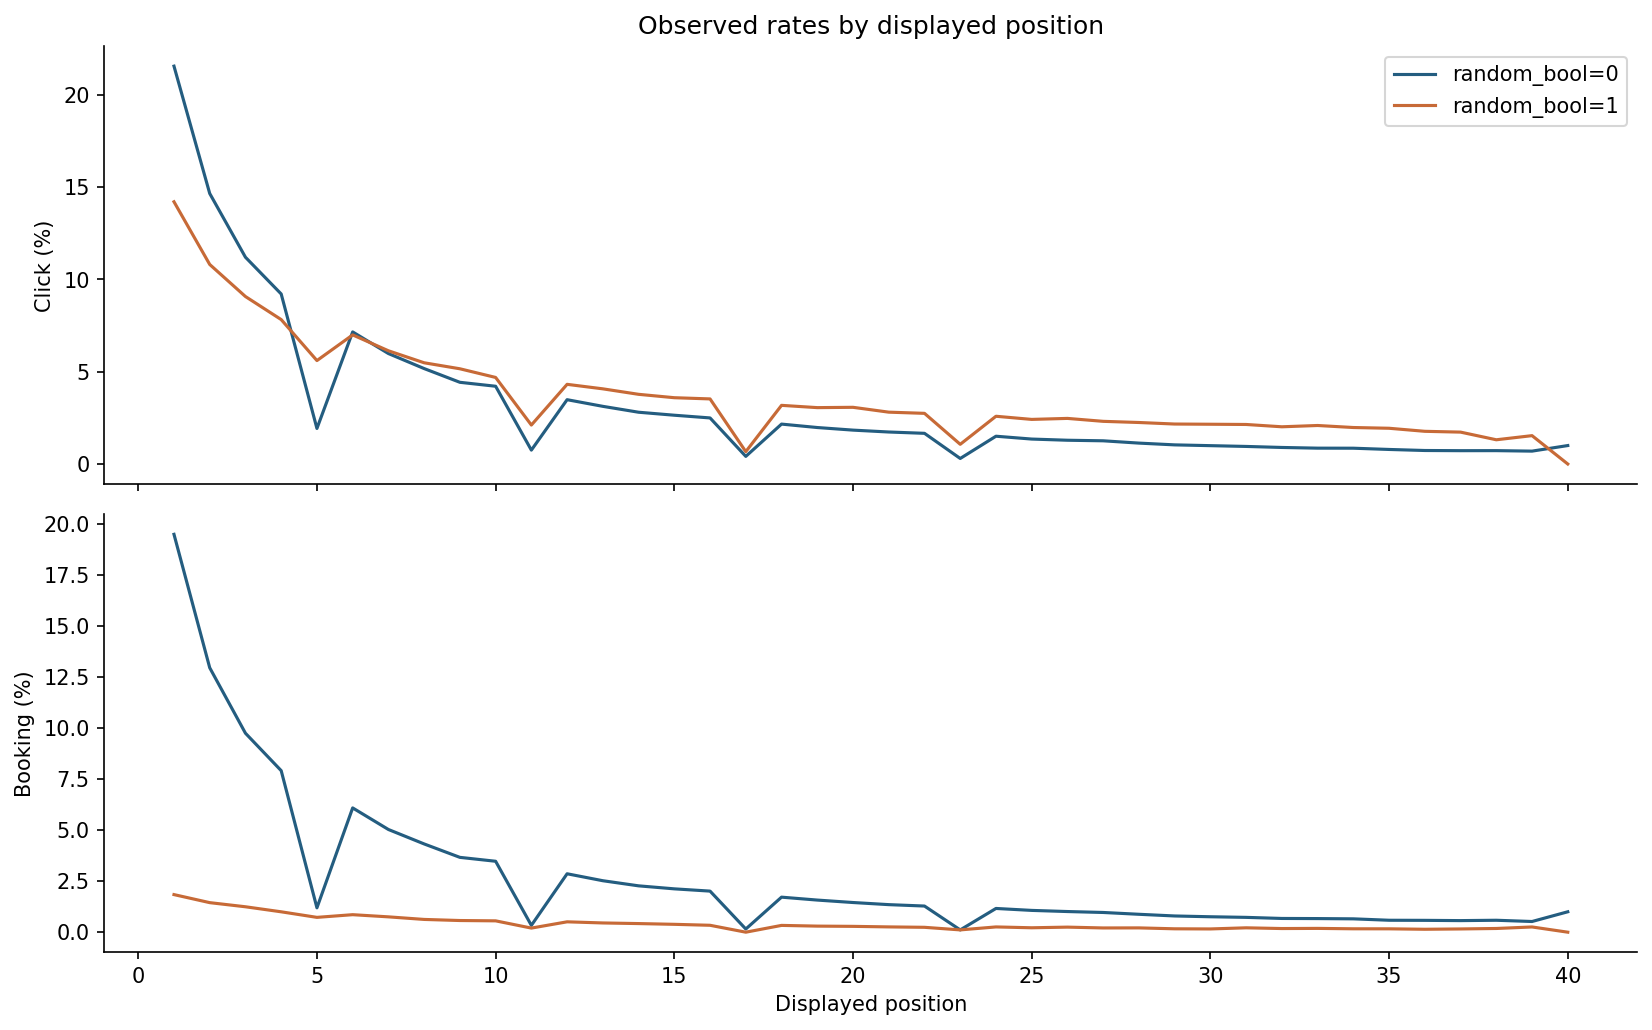

In [9]:
eda.show_section(report, 'position')

## 9. Thời gian và so sánh train–test

Khoảng thời gian và phân bố category được tính trực tiếp, không giả định test nằm sau train. Tháng đầu/cuối có thể không đầy đủ. Total variation so sánh phân phối category ở cấp dòng, không đại diện đầy đủ cho drift ở cấp search/user. Test không có nhãn nên không tính click/booking rate cho test. Bất kỳ đánh giá tương lai nào ở giai đoạn sau cần giữ nguyên srch_id trong một tập và thiết kế thời gian theo mục tiêu triển khai; chưa thực hiện chia tập ở đây.

**Khoảng thời gian toàn bộ mỗi tập**

,population,min_date_time,max_date_time,searches
0,train,2012-11-01 00:01:37,2013-06-30 23:58:24,399344
1,test,2012-11-01 00:03:24,2013-06-30 23:57:15,266230


**Train: tỷ lệ theo tháng**

,year_month,n,clicks,bookings,click_pct,booking_pct
0,2012-11,990772,44309,28013,4.4722,2.8274
1,2012-12,957195,42372,26708,4.4267,2.7902
2,2013-01,1224353,53459,32196,4.3663,2.6296
3,2013-02,1177863,52119,32580,4.4249,2.7660
4,2013-03,1400821,62848,38738,4.4865,2.7654
5,2013-04,1291801,58209,36169,4.5060,2.7999
6,2013-05,1397042,63658,39950,4.5566,2.8596
7,2013-06,1477683,66698,42239,4.5137,2.8585


**Khác biệt category train–test, toàn bộ dòng**

,column,total_variation_0_1,test_only_categories
2,prop_country_id,0.0053,2
1,visitor_location_country_id,0.0048,5
0,site_id,0.0025,0
6,srch_saturday_night_bool,0.0014,0
7,random_bool,0.0010,0
3,prop_starrating,0.0008,0
4,prop_brand_bool,0.0002,0
5,promotion_flag,0.0002,0


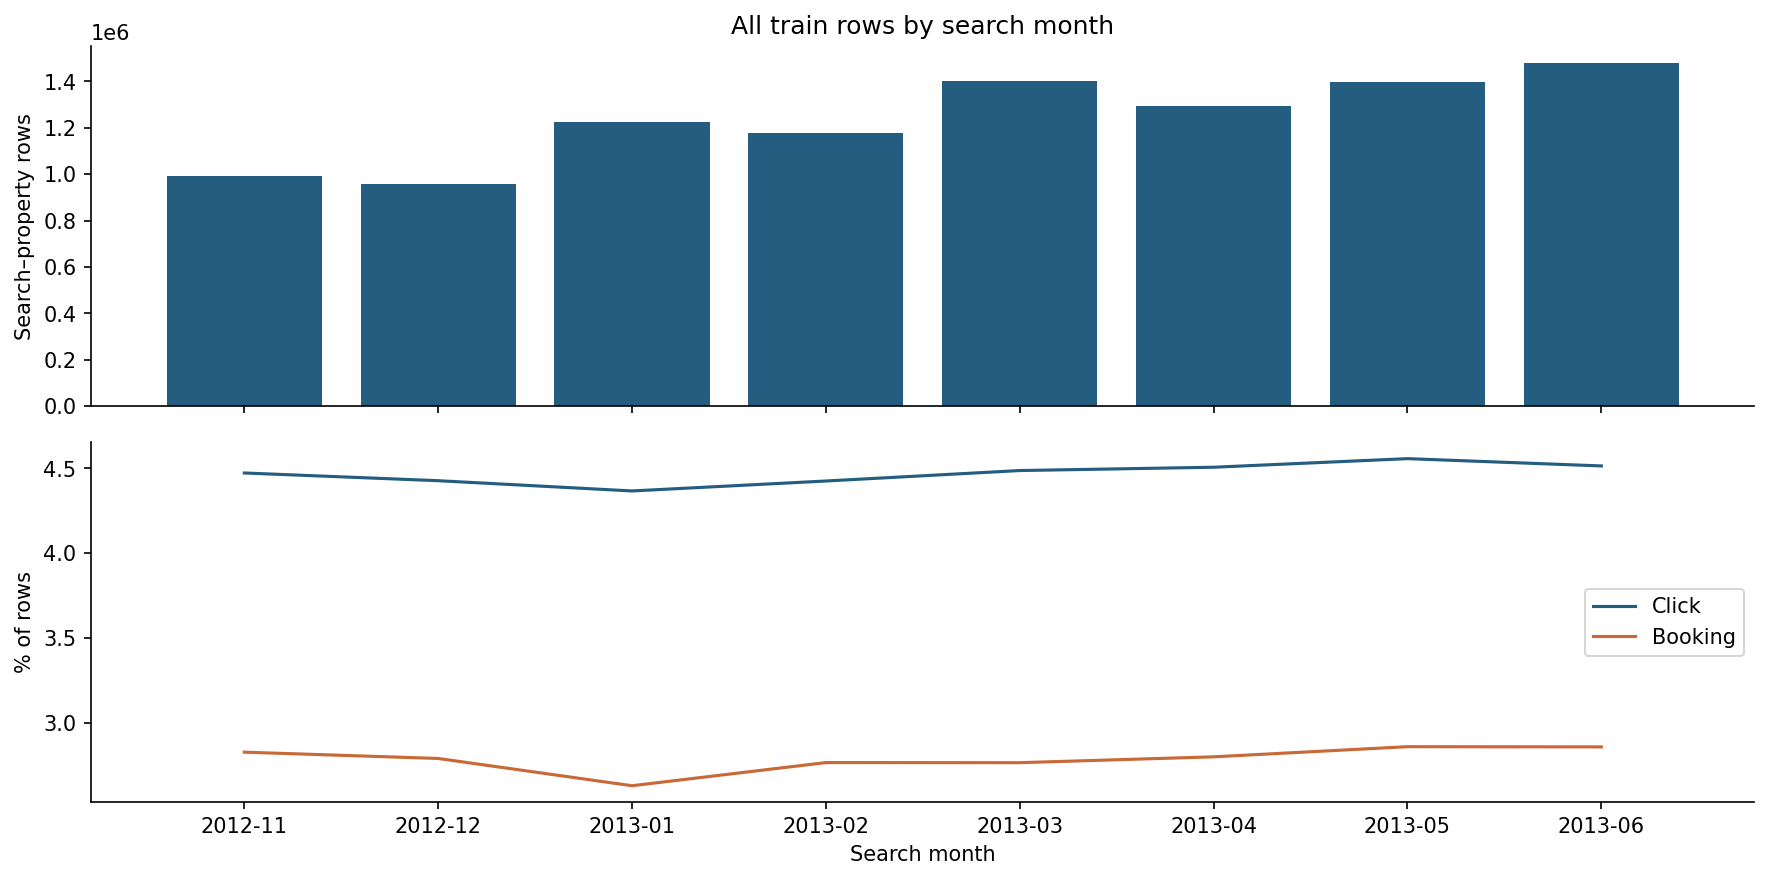

In [10]:
eda.show_section(report, 'time')

## 10. Phụ thuộc giữa các biến trên mẫu nhóm

In [11]:
eda.show_section(report, 'dependencies')

Tương quan Spearman dưới đây dùng mẫu hash theo search và các cặp không thiếu. Đây là kiểm tra mô tả cho một danh sách biến đã công bố, không phải chọn feature. Biến ngữ cảnh được lặp cho nhiều khách sạn cùng search, nên không diễn giải số dòng như số người độc lập. Giá, hạng sao, vị trí và giá lịch sử có thể chứa thông tin chồng lặp; chưa loại hoặc kết hợp cột.

**12 cặp có |rho| lớn nhất trên mẫu nhóm**

,column_a,column_b,sample_spearman_rho
4,price_usd,prop_log_historical_price,0.5773
0,price_usd,prop_starrating,0.5548
21,prop_location_score1,prop_location_score2,0.5292
11,prop_starrating,prop_log_historical_price,0.5019
8,prop_starrating,prop_review_score,0.4251
1,price_usd,prop_review_score,0.4208
17,prop_review_score,prop_log_historical_price,0.3472
33,srch_length_of_stay,srch_booking_window,0.3463
22,prop_location_score1,prop_log_historical_price,0.3201
9,prop_starrating,prop_location_score1,0.3196


## 11. Kết luận và câu hỏi còn mở

In [12]:
eda.show_section(report, 'conclusions')

**Đã kiểm chứng trên toàn bộ train:** 9,917,530 cặp search-property thuộc 399,344 searches; click 4.47%, booking 2.79%, booking/click 62.34%. Không có search hoàn toàn không click trong tập train hiện tại. Số cột đối thủ là 24 và tỷ lệ missing khác nhau mạnh theo đối thủ. Gross bookings là kết quả; position không có trong test.

**Mức độ phù hợp:** phù hợp nghiên cứu propensity/xếp hạng ở cấp khách sạn trong search, chưa phải propensity marketing theo user hoặc CTR/CVR toàn website. Two-stage click/booking là một khả năng định nghĩa bài toán, không phải kết luận bắt buộc từ tỷ số booking/click cao.

**Cần xác minh:** cơ chế đưa search vào dữ liệu và nhóm không click bị thiếu; tính sẵn có của từng điểm do Expedia sinh; nghĩa/đơn vị và cách hình thành giá; quy trình random_bool; khả năng nhận diện người dùng và lần tìm kiếm lặp; phạm vi áp dụng ngoài dữ liệu lịch sử.

Không class weighting, resampling, imputation, clipping, encoding, feature engineering hay train/rank model. Không tạo tập processed hoặc tự quyết định loại cột missing cao. Các câu hỏi và thống kê ở đây phục vụ hiểu dữ liệu trước giai đoạn tiếp theo.

## Tái lập và kiểm soát phạm vi

In [13]:
eda.show_section(report, 'reproducibility')

Chạy notebook theo thứ tự từ đầu, hoặc chạy `python scripts/build_descriptive_reports.py` tại thư mục gốc để dựng lại toàn bộ. Script chỉ đọc CSV raw, viết báo cáo/biểu đồ và lưu notebook trong notebooks/; không sửa raw, không ghi data/processed, không gọi pipeline huấn luyện. Các thời điểm phân tích dùng Asia/Ho_Chi_Minh. SHA-256 ở danh mục file nhận diện nguồn; số dòng theo CSV parser được đối chiếu với data_lines của file chính. Các bảng nhóm chỉ sống trong bộ nhớ để tính EDA. Script thực thi các cell bằng IPython trong cùng tiến trình và lưu output thật vào notebook; không khởi tạo kernel mạng. Phụ thuộc dựng báo cáo gồm pandas, numpy, matplotlib, nbformat và IPython; có thể mở notebook bằng Jupyter để Run All.

**Môi trường thực thi**

,component,value
0,Python,3.14.2
1,pandas,2.3.3
2,numpy,2.4.1
3,matplotlib,3.10.8
4,Phương pháp,"Thống kê mô tả, không mô hình"
5,Chunk CSV lớn,250000
